## Comparison of experimental evolutionary trajectories with global observational trajectories



## 0. General 

### 0.1. Load libraries

In [1]:
import os, pandas as pd, numpy as np, json, random
from Bio import SeqIO
from Bio.Seq import Seq
from scipy.stats import linregress, t

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec

import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 9
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True


### 0.2. General variables

In [3]:
detection_limit = 0.01

In [4]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]
segments = ["1-PB2", "2-PB1", "3-PA", "4-HA", "5-NP", "6-NA", "7-M", "8-NS"]
proteins = ['PB2', 'PB1', 'PB1-F2', 'PA', 'PA-X', 'HA', 'NP', 'NA', 'M1', 'M2', 'NEP', 'NS1']


hours_per_passage = 72 #hours
generation_time = 6 #hours > assumption based on Baccam, et al. 2006

In [5]:
#color palette 
population_cpal = [ "#005fb9", "#58b4e2", "#8ee6ff", "#860041", "#ca0090", "#ff53c0", "#006e00", "#77a908", "#bbe837", "#0000ba", "#5f38ed", "#d49eff" ]
nonsyn_color = "#d90368"
syn_color = "#fb8b24"

In [6]:
with open('../data/CDS_H3N2.json') as json_file:
    coding_json = json.load(json_file)
segment_nuc_cds = {r.id:r.seq for r in SeqIO.parse('../data/references/stock_consensus_cds.fasta', 'fasta')}

aapos2codon = {}
nucpos2aapos = {}
for segment, pdict in coding_json.items():
    aapos2codon[segment] = {}
    nucpos2aapos[segment] = {}
    for protein, posdict in pdict.items():
        aapos2codon[segment][protein] = {}
        
        for aapos in np.arange(1, posdict["pro_aa_pos"][-1]+1):
            nucpos = [posdict["nuc_cds_pos"][i] for i, aap in enumerate(posdict["pro_aa_pos"]) if aap == aapos]
            aapos2codon[segment][protein][aapos] = nucpos
    
        nucpos2aapos[segment][protein] = {nucpos:posdict["pro_aa_pos"][i] for i, nucpos in enumerate(posdict["nuc_cds_pos"])}



In [7]:

codon_table = {'ATA':'I', 'ATC':'I', 'ATT':'I', 'ATG':'M', 'ACA':'T', 'ACC':'T', 'ACG':'T', 'ACT':'T', 'AAC':'N',
               'AAT':'N', 'AAA':'K', 'AAG':'K', 'AGC':'S', 'AGT':'S', 'AGA':'R', 'AGG':'R', 'CTA':'L', 'CTC':'L',
               'CTG':'L', 'CTT':'L', 'CCA':'P', 'CCC':'P', 'CCG':'P', 'CCT':'P', 'CAC':'H', 'CAT':'H', 'CAA':'Q',
               'CAG':'Q', 'CGA':'R', 'CGC':'R', 'CGG':'R', 'CGT':'R', 'GTA':'V', 'GTC':'V', 'GTG':'V', 'GTT':'V',
               'GCA':'A', 'GCC':'A', 'GCG':'A', 'GCT':'A', 'GAC':'D', 'GAT':'D', 'GAA':'E', 'GAG':'E', 'GGA':'G',
               'GGC':'G', 'GGG':'G', 'GGT':'G', 'TCA':'S', 'TCC':'S', 'TCG':'S', 'TCT':'S', 'TTC':'F', 'TTT':'F', 
               'TTA':'L', 'TTG':'L', 'TAC':'Y', 'TAT':'Y', 'TAA':'*', 'TAG':'*', 'TGC':'C', 'TGT':'C', 'TGA':'*',
               'TGG':'W'}

aa_codons = {aa:[codon for codon, a in codon_table.items() if a == aa] for aa in set(codon_table.values())}

valid_nucs = ["a", "c", "t", "g"]

In [8]:
blosum62 = pd.read_csv("../data/blosum62.csv", index_col=0)


In [9]:
TnTv = 11.75
weight_Tn = 3 * TnTv / (1 + TnTv)
weight_Tv = (3 - weight_Tn) / 2

In [10]:
#HA specific variable
start_mature_HA =17
HA_signal_peptide_length = 16
HA1_length = 329

epitope_sites= {"A":[122,124,126,127,130,131,132,133,135,137,138,140,142,143,144,145,146,150,152,168], 
                "B":[128,129,155,156,157,158,159,160,163,164,165,186,187,188,189,190,192,193,194,196,197,198], 
                "C":[44,45,46,47,48,49,50,51,53,54,273,275,276,278,279,280,294,297,299,300,304,305,307,308,309,310,311,312], 
                "D":[96,102,103,117,121,167,170,171,172,173,174,175,176,177,179,182,201,203,205,207,208,209,212,213,214,215,216,217,218,219,226,227,228,229,230,238,240,242,244,246,247,248,], 
                "E":[57,59,62,63,67,75,78,80,81,82,83,86,87,88,91,92,94,109,260,261,262,265,266]}
epitope_positions = [s for sites in epitope_sites.values() for s in sites]


### 0.3. Functions

In [11]:
def merge_multiple_cells(table, cell_indices):
    if len(cell_indices) < 2:
        return

    #convert to array
    cells_arr = np.array(cell_indices)
    rows = cells_arr[:, 0]
    cols = cells_arr[:, 1]
    
    min_r, max_r = rows.min(), rows.max()
    min_c, max_c = cols.min(), cols.max()
    
    #figure out the outer boundaries of the merged block
    for (r, c) in cell_indices:
        edges = ''
        if r == min_r: edges += 'T'
        if r == max_r: edges += 'B'
        if c == min_c: edges += 'L'
        if c == max_c: edges += 'R'
        
        table[r, c].visible_edges = edges
        
    primary_idx = cell_indices[0] # text starts in first cell
    primary_txt = table[primary_idx[0], primary_idx[1]].get_text()
    
    #hide text in all other cells
    for (r, c) in cell_indices[1:]:
        table[r, c].get_text().set_visible(False)

In [12]:
def score_codon_position(codon, position, target_AA):
  
    score = 0
    for b in ["A", "C", "T", "G"]:
        if b == codon[position]: continue
        
        #determine if mutation was a transition or a transversion and assign weight
        weight = weight_Tn if f'{codon[position]}{b}' in ["AG", "GA", "CT", "TC"] else weight_Tv
        
        
        mutated_codon = codon[:position] + b + codon[position+1:]
        aa = mutated_codon.translate()
        if aa == target_AA:
            score += weight/3.0 #division by 3 for single codon fraction

    return score

def score_codon_for_stops(codon):
    return sum(score_codon_position(codon, i, "*") for i in range(3))

def count_stop_codon_sites(codons):
    return sum(score_codon_for_stops(codon) for codon in codons)

def score_codon_for_syn(codon):
    return sum(score_codon_position(codon, i, codon.translate()) for i in range(3))

def count_syn_codon_sites(codons):
    return sum(score_codon_for_syn(codon) for codon in codons) 

In [13]:
def determine_gene_mutation_type(segment, gene, segment_mutation):
    gene_nuc_pos = coding_json[segment][gene]["nuc_cds_pos"]
    ref_gene_seq = Seq("".join([b for i,b in enumerate(segment_nuc_cds[segment]) if i+1 in gene_nuc_pos]))
    mut_segment_seq = [b if i+1 != int(segment_mutation[1:-1]) else segment_mutation[-1] for i, b in enumerate(segment_nuc_cds[segment])]
    mut_gene_seq = Seq("".join([b for i,b in enumerate(mut_segment_seq) if i+1 in gene_nuc_pos]))
    
    #get codon pos
    codon_pos = coding_json[segment][gene]['pro_aa_pos'][coding_json[segment][gene]['nuc_cds_pos'].index(int(segment_mutation[1:-1]))]

    ref_aa_seq = ref_gene_seq.translate()
    mut_aa_seq = mut_gene_seq.translate()
    
   
    if mut_aa_seq[codon_pos-1] == ref_aa_seq[codon_pos-1]:
        return "syn"
    elif  mut_aa_seq[codon_pos-1] == "*":
        return "stop"
    else:
        return "ns"

def determine_global_snvs(ref, global_seq):
    valid_nucs = ["A", "C", "T", "G"]
    muts = []
    
    global_seq = global_seq.upper()
    for i, b in enumerate(global_seq):
        if b not in valid_nucs:
            continue
        if b != ref[i]:
            muts.append(f"{ref[i]}{i+1}{b}")
    
    return muts

def determine_H3_mutation_type(snv):
    #snv h3_numbering
    ref_seq = Seq("".join([b for i,b in enumerate(segment_nuc_cds["4-HA"]) if i+1 in coding_json['4-HA']["HA"]['nuc_cds_pos'] and coding_json['4-HA']["HA"]['pro_aa_pos'][i]>16]))
    if snv[-1] == "*":
        return "stop"
    
    mut_seq = list(ref_seq)
    mut_seq[int(snv[1:-1])-1] = snv[-1]
    mut_seq = Seq("".join(mut_seq))
    
    if mut_seq.translate() != ref_seq.translate():
        return "ns"
    else:
        return "syn"
    

## 1. AA observations verus global AA frequencies

### 1.1. Access overall global conservation

In [14]:
global_observation_resolution = {"pre-2008":['1968-1972','1973-1977','1978-1982','1982-1987', '1988-1992','1993-1997','1998','1999','2000','2001','2002','2003','2004','2005','2006','2007'],
                                 "post-2008":['1998','1999','2000','2001','2002','2003','2004','2005','2006','2007', '2008','2009','2010','2011','2012','2013','2014','2015','2016','2017', '2018','2019','2020','2021','2022','2023','2024','2025'],
                                 "1968-1977": ['1968-1972','1973-1977'],
                                 "1978-1987": ['1978-1982','1982-1987'],
                                 "1988-1997": ['1988-1992','1993-1997'],
                                 "1998-2007": ['1998','1999','2000','2001','2002','2003','2004','2005','2006','2007'],
                                 "2008-2017": ['2008','2009','2010','2011','2012','2013','2014','2015','2016','2017',],
                                 "2018-2025": ['2018','2019','2020','2021','2022','2023','2024','2025']}

In [15]:
#global frequencies estimated from gisaid data
global_aa_freq_dir = "../results/global_data/global_AA_frequencies"

AA_list = list(sorted(aa_codons.keys()))

minimum_global_freq = 0.1
print ("Global conservation")
for protein in proteins:
    
    if protein in ["PB1-F2", "PA-X"]:continue
    global_frequencies = pd.read_csv(os.path.join(global_aa_freq_dir, f"H3_{protein}_global_AA_frequencies.csv")).set_index(["position", "time_window"])

    conserved_positions = 0
    not_conserved_positions = 0
    for position in global_frequencies.index.get_level_values(0).unique():
        df = global_frequencies.loc[position]
        unique_AAs = []
        for AA in AA_list:

            if len(df[df[AA]>=minimum_global_freq])>0:
                unique_AAs.append(AA)
        if len(unique_AAs) >1:
            not_conserved_positions += 1
            
        else:
            conserved_positions += 1
            
    tot = conserved_positions + not_conserved_positions

    print (f"{protein} {round((conserved_positions/tot)*100,2)}% conserved ({conserved_positions}/{tot})")



Global conservation
PB2 91.97% conserved (699/760)
PB1 94.33% conserved (715/758)
PA 92.19% conserved (661/717)
HA 74.43% conserved (422/567)
NP 89.18% conserved (445/499)
NA 75.53% conserved (355/470)
M1 92.89% conserved (235/253)
M2 76.53% conserved (75/98)
NEP 92.13% conserved (117/127)
NS1 70.17% conserved (167/238)


### 1.2. Compared observed AA to global AA conservation

In [16]:
#load data
#load snv summary 
snv_summary = pd.read_csv("../results/snv_summary_annotated_linkage_bias.csv", keep_default_na=False, na_values=[""]).set_index(["population", "refname", "nucpos", "snv"]).sort_index()

#create overview of non-synonymous SNVs (for convienence)
non_synonymous_dict = {segment:[] for segment in segments}
for i in snv_summary[snv_summary["non_synonymous"]==True].index.droplevel(0):
    non_synonymous_dict[i[0]].append(i[-1])

In [17]:
# compared_ns_global = snv_summary[(snv_summary["non_synonymous"]==True)&(snv_summary["status"]!="drift")].copy()
compared_ns_global = snv_summary[(snv_summary["non_synonymous"]==True)].copy()
compared_ns_global = compared_ns_global[["protein", "aapos", "aa_mut", "status"]]

compared_ns_global[["conserved", "globally observed", "globally observed AAs"]] = [True, False, np.NaN, ]

compared_ns_global = compared_ns_global.reset_index().set_index(["protein", "aapos", "aa_mut"]).sort_index()

# for global_level, tf_list in global_observation_resolution.items():
#     compared_ns_global[global_level] = ""
#     compared_ns_global[global_level] = compared_ns_global[global_level].astype(str)



AA_list = list(sorted(aa_codons.keys()))

minimum_global_freq = 0.1

aa_observations_level = {"fixed":0.97, "consensus":0.5, "minor":0.1}

for protein in proteins:
    global_frequencies = pd.read_csv(os.path.join(global_aa_freq_dir, f"H3_{protein}_global_AA_frequencies.csv")).set_index(["position", "time_window"])
    global_timewindows = global_frequencies.index.get_level_values(1).unique().tolist()
    
    
    df = compared_ns_global.loc[protein]
    
    for aapos in df.index.get_level_values(0).unique():
        
        aadf = global_frequencies.loc[aapos]
        
        aa_observations = {tf:{}for tf in aadf.index.unique()}
        aa_observed = []
        for tf in aadf.index.unique():

            tfd = aadf.loc[tf].to_dict()
            for aa in AA_list:
                if tfd[aa]>= minimum_global_freq:
                    aa_observations[tf][aa] = tfd[aa]
                    if aa not in aa_observed:
                        aa_observed.append(aa)
 
        conserved = True if all(len(v)==1 for v in aa_observations.values()) else False
        conserved = True if len(aa_observed)<2 else False
        #conserved = True if all(len(v)==1 for v in aa_observations.values()) else True if len(aa_observed)>1 else False
       
        sdf = df.loc[aapos]
        
        for aa_mut, row in sdf.iterrows():

            aa = aa_mut[-1]
            
            for global_level, tf_list in global_observation_resolution.items():
                obs_levels = []
                for tf in tf_list:
                    if aa in aa_observations[tf].keys():
                        f = aa_observations[tf][aa]
                        for level, fcutoff in aa_observations_level.items():
                            if f>= fcutoff:
                                obs_levels.append(level)
                                break
                if len(obs_levels) > 0:
                    obs_level = [l for l in aa_observations_level.keys() if l in obs_levels][0]
                    compared_ns_global.loc[(protein, aapos, aa_mut), global_level] = obs_level
                    compared_ns_global.loc[(protein, aapos, aa_mut), "globally observed"] = True

            compared_ns_global.loc[(protein, aapos, aa_mut), "conserved"] = conserved
            compared_ns_global.loc[(protein, aapos, aa_mut), "globally observed AAs"] = ", ".join(aa_observed)

compared_ns_global = compared_ns_global.reset_index().set_index(["population", "refname", "nucpos", "snv"]).sort_index()

    

/var/folders/3r/pf10m1dj4lg0cf02535yqnlm0000gn/T/ipykernel_58310/1360000810.py:68: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'E' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  compared_ns_global.loc[(protein, aapos, aa_mut), "globally observed AAs"] = ", ".join(aa_observed)


In [18]:
sum_ns_global = snv_summary[(snv_summary["non_synonymous"]==True)].copy()
sum_ns_global = sum_ns_global[~sum_ns_global["protein"].isin(["PB1-F2", "PA-X"])]
sum_ns_global  = sum_ns_global[["protein", "aapos", "aa_mut", "status"]]

sum_ns_global[["conserved", "globally observed", "globally observed AAs"]] = [True, False, np.NaN, ]

sum_ns_global = sum_ns_global.reset_index().set_index(["protein", "aapos", "aa_mut"]).sort_index()

for i in sum_ns_global.index.unique():
    sum_ns_global.loc[i, "populations"] = ", ".join(sum_ns_global.loc[i, "population"])
    sum_ns_global.loc[i, "status"] = ", ".join(sum_ns_global.loc[i, "status"])
    
sum_ns_global = sum_ns_global.drop(columns=["population"]).reset_index().drop_duplicates().set_index(["protein", "aapos", "aa_mut"]).sort_index()

for protein in proteins:
    if protein in ["PB1-F2", "PA-X"]:continue
    global_frequencies = pd.read_csv(os.path.join(global_aa_freq_dir, f"H3_{protein}_global_AA_frequencies.csv")).set_index(["position", "time_window"]).sort_index()
    global_timewindows = global_frequencies.index.get_level_values(1).unique().tolist()
    
    
    df = sum_ns_global.loc[protein]
    
    for aapos in df.index.get_level_values(0).unique():
        
        aadf = global_frequencies.loc[aapos]
        
        aa_observations = {tf:{}for tf in aadf.index.unique()}
        aa_observed = []
        for tf in aadf.index.unique():

            tfd = aadf.loc[tf].to_dict()
            for aa in AA_list:
                if tfd[aa]>= minimum_global_freq:
                    aa_observations[tf][aa] = tfd[aa]
                    if aa not in aa_observed:
                        aa_observed.append(aa)
                    
        conserved = True if all(len(v)==1 for v in aa_observations.values()) else False
        conserved = True if len(aa_observed)<2 else False

        
        
        sdf = df.loc[aapos]
        
        for aa_mut in sdf.index.unique():
            
            aa = aa_mut[-1]
            for k,v in aadf[aa].to_dict().items():
                sum_ns_global.loc[(protein, aapos, aa_mut), k] = v
        
            sum_ns_global.loc[(protein, aapos, aa_mut), "conserved"] = conserved
        
            sum_ns_global.loc[(protein, aapos, aa_mut), "globally observed AAs"] = ", ".join(aa_observed)
            sum_ns_global.loc[(protein, aapos, aa_mut), "globally observed"] = True if aa in aa_observed else False
        

/var/folders/3r/pf10m1dj4lg0cf02535yqnlm0000gn/T/ipykernel_58310/3474128724.py:53: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'E' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  sum_ns_global.loc[(protein, aapos, aa_mut), "globally observed AAs"] = ", ".join(aa_observed)


In [19]:
sum_ns_global = sum_ns_global.reset_index().set_index(["refname", "nucpos", "snv", "protein", "aapos"]).sort_index()

sum_ns_global_filter = sum_ns_global[sum_ns_global["status"].isin([s for s in sum_ns_global["status"].unique() if len([l for l in s.split(", ") if l != "drift"])>0])]
sum_ns_global_filter = sum_ns_global_filter[~sum_ns_global_filter.index.get_level_values(2).isin(["PB1-F2", "PA-X"])]

sum_ns_global_filter = sum_ns_global_filter[sum_ns_global_filter["conserved"]!=True]
sum_ns_global_filter_observed = sum_ns_global_filter[sum_ns_global_filter["globally observed"]==True]
sum_ns_global_filter_not = sum_ns_global_filter[sum_ns_global_filter["globally observed"]==False]


/var/folders/3r/pf10m1dj4lg0cf02535yqnlm0000gn/T/ipykernel_58310/2904982616.py:67: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df.loc[("1-PB2", 1, "n", "PB2", 1)] = [0]*len(global_timewindows)


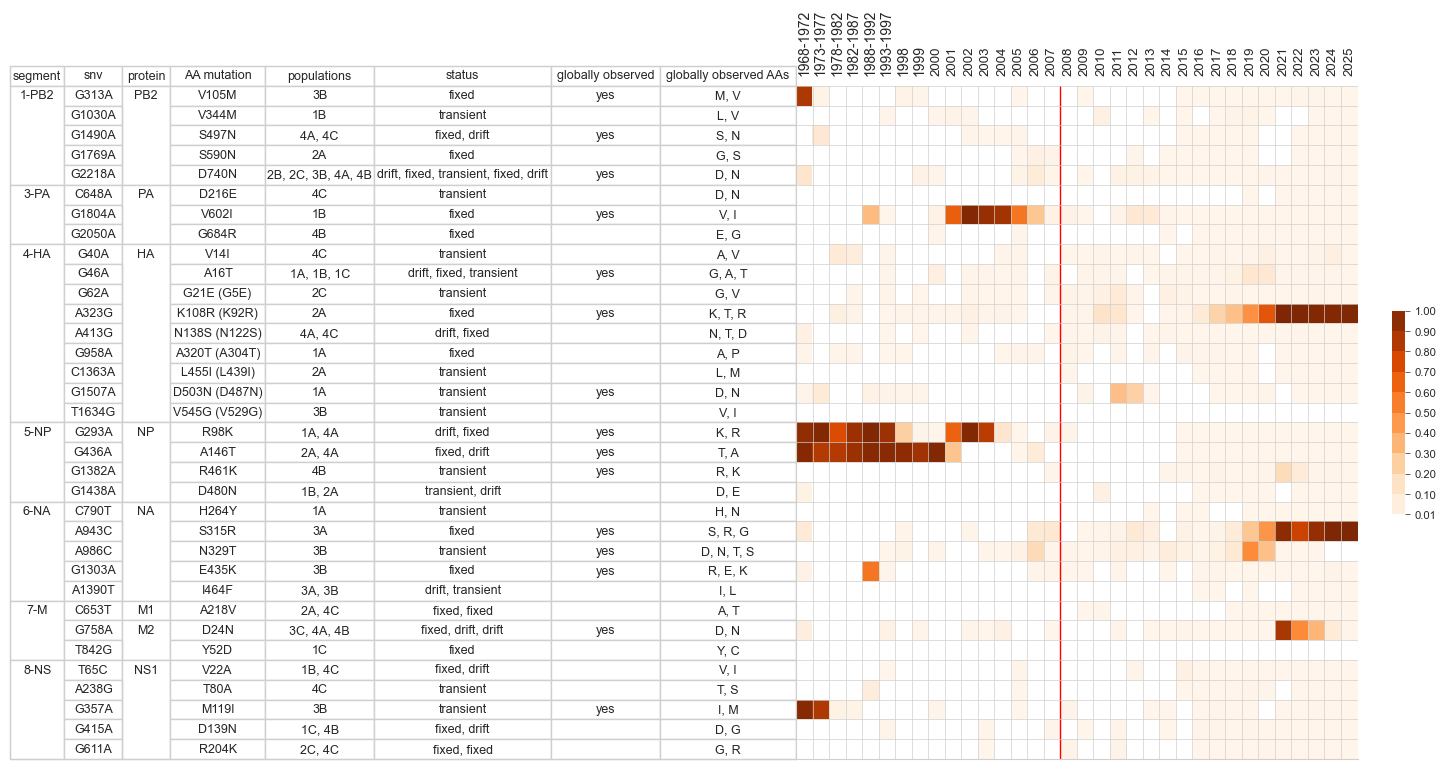

In [20]:
fig = plt.figure(figsize=(18,9))

gs = gridspec.GridSpec(1,2, wspace=0.05, hspace=0.5, width_ratios=[1, 0.01])

gsi =gridspec.GridSpecFromSubplotSpec(1, 2, wspace=0.0, subplot_spec=gs[0], width_ratios=[1.4,1])

ax = fig.add_subplot(gsi[0])

df = sum_ns_global_filter.reset_index()

df = df[[c for c in df.columns if c not in global_timewindows and c not in ["conserved", "nucpos", "aapos"]]]
df = df[["refname", "snv", "protein", "aa_mut", "populations", "status", "globally observed", "globally observed AAs",]]
df["globally observed"] = np.where(df["globally observed"], "yes", "")
df["populations"] = [", ".join([p for p in row["populations"].split(", ")]) for _,row in df.iterrows()]

for i, row in df.iterrows():
    if row["protein"] == "HA":
        h3_pos = int(row["aa_mut"][1:-1]) - 16
        if h3_pos < 1:
            continue
        h3_mut = row["aa_mut"].replace(row["aa_mut"][1:-1], str(h3_pos))
        df.loc[i, "aa_mut"] = f'{row["aa_mut"]} ({h3_mut})'
    
df = df.rename(columns={"refname":"segment", "aa_mut":"AA mutation"})

table = ax.table(cellText=df.values, colLabels=df.columns, bbox=[0, 0, 1, 1], fontsize=9 )
table.auto_set_font_size(False)
# table.scale(2, 2)

column_width_weights = {"segment": 0.8,"snv": 0.85,"protein": 0.7,"AA mutation": 1.4,"populations": 1.6,"status": 2.6, "globally observed":1.6, "globally observed AAs": 2. }

# Convert your custom weights into percentages that sum to 1.0
ordered_weights = [column_width_weights[col] for col in df.columns]
total_weight = sum(ordered_weights)
proportional_widths = [w / total_weight for w in ordered_weights]

# Assign the beautifully tuned widths to every cell
for (row, col), cell in table.get_celld().items():
    cell.set_width(proportional_widths[col])

# table.auto_set_column_width(col=list(range(len(df.columns))))
border_color = "#CFCFCF" 
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor(border_color)
     
    
    cell.get_text().set_ha('center') 
    cell.set_text_props(wrap=True) 

for segment in df["segment"].unique():
    cells_to_merge = [(x+1, 0) for x, s in enumerate(df["segment"]) if s==segment] #
    merge_multiple_cells(table, cells_to_merge)
for protein in df["protein"].unique():
    cells_to_merge = [(x+1, 2) for x, s in enumerate(df["protein"]) if s==protein] #
    merge_multiple_cells(table, cells_to_merge)
    
    
ax.tick_params(axis="both", length=0)
ax.set_xticks([])
ax.set_yticks([])
ax.spines[['top','right', "left", 'bottom']].set_color(border_color)

    
ax = fig.add_subplot(gsi[1])
plot_df = sum_ns_global_filter[global_timewindows]
#inventing a fake row
plot_df.loc[("1-PB2", 1, "n", "PB2", 1)] = [0]*len(global_timewindows)
plot_df = plot_df.sort_index()
masked_data = np.ma.masked_equal(plot_df.values, 0)
im = ax.imshow(masked_data,aspect='auto', cmap="Oranges") 
ax.tick_params(axis="both", length=0)
ax.set_xticks([])
ax.set_yticks([])
ax.spines[['top','right', "left", 'bottom']].set_color(border_color)
ax.spines[['top','right']].set_visible(False)


for i, tw in enumerate(global_timewindows):
    ax.text(i, -0, str(tw), rotation=90, va="bottom", ha="center", size=10 if tw.startswith("1") else 9.5)
    #if tw !="2025":
    ax.axvline(i+0.5, lw=0.5, ymax=(len(plot_df)-1)/len(plot_df), color=border_color,)
    if tw == "2008":
        ax.axvline(i-0.5, lw=1, ymax=(len(plot_df)-1)/len(plot_df), color="red",)
        
  
for i in df.index.tolist():      
    ax.axhline(i+0.5, lw=0.5, color=border_color)

gsi = gridspec.GridSpecFromSubplotSpec(3, 1, subplot_spec=gs[1], height_ratios=[2,2,2])
cax = fig.add_subplot(gsi[1])

# cbar = fig.colorbar(im, cax=cax, format='%.2f')#
bounds = np.linspace(0.01, 1, 10)  # 6 discrete bins
bounds = [0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
cbar = fig.colorbar(im, cax=cax,boundaries=bounds, ticks=bounds)
cbar.ax.tick_params(labelsize=8)
cbar.outline.set_visible(False)

fig.savefig("../figures/figE7_global_observation_SNVs.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/figE7_global_observation_SNVs.png", dpi=300,bbox_inches='tight')   

**Extended Data Figure 7 Overview of observed non-drift-like AA mutations in positions that are globally not conserved.** Heatmap shows the global frequency of the observed AA mutation (e.g. for mutation V105M heatmap shows the global frequency of M). Global observation is defined as a frequency 10% in one the time windows. White cells indicate 0.0% frequency. Red lines indicate 2008. Drift observation in populations have also been included if AA observation in another population was classified as non-drift-like. Status order matches the order of the populations. For HA substitution are labelled by sequential number with H3-numbering in brackets where possible. 

### 1.3. Investigate globally conserved sites

In [21]:
sum_ns_global = sum_ns_global.reset_index().set_index(["refname", "nucpos", "snv", "protein", "aapos"]).sort_index()

sum_ns_global_cons = sum_ns_global[sum_ns_global["status"].isin([s for s in sum_ns_global["status"].unique() if len([l for l in s.split(", ") if l != "drift"])>0])]
sum_ns_global_cons = sum_ns_global_cons[~sum_ns_global_cons.index.get_level_values(2).isin(["PB1-F2", "PA-X"])]

sum_ns_global_cons = sum_ns_global_cons[sum_ns_global_cons["conserved"]==True]


In [22]:
df = sum_ns_global_cons.reset_index()
df = df[[c for c in df.columns if c not in global_timewindows and c not in ["conserved", "nucpos", "aapos"]]]
df = df[["refname", "snv", "protein", "aa_mut", "populations", "status", "globally observed AAs",]]


for i, row in df.iterrows():
    if row["protein"] == "HA":
        h3_pos = int(row["aa_mut"][1:-1]) - 16
        if h3_pos < 1:
            continue
        h3_mut = row["aa_mut"].replace(row["aa_mut"][1:-1], str(h3_pos))
        df.loc[i, "aa_mut"] = f'{h3_mut} ({row["aa_mut"]})'
    

df = df.rename(columns={"refname":"segment", "aa_mut":"AA mutation"})
df.set_index(["segment"]).to_clipboard()
df["blosum"] = [blosum62.loc[row["AA mutation"][0], row["AA mutation"].split(" ")[0][-1]] for _, row in df.iterrows()]

df["blosum"] = [blosum62.loc[row["AA mutation"][0], row["AA mutation"].split(" ")[0][-1]] for _, row in df.iterrows()]
# display(df)

c_conserved = df.groupby("protein").nunique()[["snv"]]#.to_clipboard()

c_not_conserved = sum_ns_global_filter.reset_index().groupby("protein").nunique()[["snv"]]

for protein in ["PB2", "PB1", "PA", "HA", "NP", "NA", "M1", "M2", "NS1", "NEP"]:
    if protein not in c_conserved.index.tolist():
        tot = c_not_conserved.loc[protein, "snv"]
        print (f"{protein}: 0% (0/{tot}) conserved {tot}/{tot} (100%) not conserved")
    elif protein not in c_not_conserved.index.tolist():
        tot = c_conserved.loc[protein, "snv"]
        print (f"{protein}: {tot}/{tot} (100%) conserved {0}/{tot} (0%) not conserved")
        
        
    else:
        tot = c_conserved.loc[protein, "snv"] + c_not_conserved.loc[protein, "snv"]
        print (f"{protein}: {c_conserved.loc[protein, 'snv']}/{tot} ({round((c_conserved.loc[protein, 'snv']/tot)*100,1)}%) conserved {c_not_conserved.loc[protein, 'snv']}/{tot} ({round((c_not_conserved.loc[protein, 'snv']/tot)*100,2)}%) not conserved")
        
        


PB2: 8/13 (61.5%) conserved 5/13 (38.46%) not conserved
PB1: 10/10 (100%) conserved 0/10 (0%) not conserved
PA: 16/19 (84.2%) conserved 3/19 (15.79%) not conserved
HA: 4/13 (30.8%) conserved 9/13 (69.23%) not conserved
NP: 6/10 (60.0%) conserved 4/10 (40.0%) not conserved
NA: 12/17 (70.6%) conserved 5/17 (29.41%) not conserved
M1: 3/4 (75.0%) conserved 1/4 (25.0%) not conserved
M2: 1/3 (33.3%) conserved 2/3 (66.67%) not conserved
NS1: 4/9 (44.4%) conserved 5/9 (55.56%) not conserved
NEP: 2/2 (100%) conserved 0/2 (0%) not conserved


In [23]:
df = sum_ns_global[(sum_ns_global["conserved"]==False)&(sum_ns_global["globally observed"]==False)&(sum_ns_global["status"]!="drift")].copy()
df["blosum"] = [blosum62.loc[row["aa_mut"][0], row["aa_mut"].split(" ")[0][-1]] for _, row in df.iterrows()]
display(df[df["blosum"]<0])

aa_mut        status  conserved  \
refname nucpos snv    protein aapos                                   
3-PA    2050   G2050A PA      684.0  G684R         fixed      False   
4-HA    62     G62A   HA      21.0    G21E     transient      False   
        194    G194A  HA      65.0    G65D  drift, drift      False   
        1634   T1634G HA      545.0  V545G     transient      False   
6-NA    59     T59C   NA      20.0    I20T  drift, drift      False   
7-M     842    T842G  M2      52.0    Y52D         fixed      False   

                                     globally observed globally observed AAs  \
refname nucpos snv    protein aapos                                            
3-PA    2050   G2050A PA      684.0              False                  E, G   
4-HA    62     G62A   HA      21.0               False                  G, V   
        194    G194A  HA      65.0               False                  G, S   
        1634   T1634G HA      545.0              False                  V, I   
6-NA    59     T59C   NA      20.0               False                  I, V   
7-M     842    T842G  M2      52.0               False                  Y, C   

                                    populations  1968-1972  1973-1977  \
refname nucpos snv    protein aapos                                     
3-PA    2050   G2050A PA      684.0          4B        0.0        0.0   
4-HA    62     G62A   HA      21.0           2C        0.0        0.0   
        194    G194A  HA      65.0       1A, 4B        0.0        0.0   
        1634   T1634G HA      545.0          3B        0.0        0.0   
6-NA    59     T59C   NA      20.0       1B, 1C        0.0        0.0   
7-M     842    T842G  M2      52.0           1C        0.0        0.0   

                                     1978-1982  1982-1987  ...      2017  \
refname nucpos snv    protein aapos                        ...             
3-PA    2050   G2050A PA      684.0        0.0   0.000000  ...  0.002503   
4-HA    62     G62A   HA      21.0         0.0   0.005435  ...  0.001891   
        194    G194A  HA      65.0         0.0   0.000000  ...  0.000579   
        1634   T1634G HA      545.0        0.0   0.000000  ...  0.000000   
6-NA    59     T59C   NA      20.0         0.0   0.000000  ...  0.001503   
7-M     842    T842G  M2      52.0         0.0   0.000000  ...  0.000000   

                                         2018      2019      2020      2021  \
refname nucpos snv    protein aapos                                           
3-PA    2050   G2050A PA      684.0  0.000707  0.000926  0.000887  0.002098   
4-HA    62     G62A   HA      21.0   0.005049  0.002101  0.001914  0.000920   
        194    G194A  HA      65.0   0.000560  0.000525  0.001913  0.000550   
        1634   T1634G HA      545.0  0.000000  0.000000  0.000000  0.000000   
6-NA    59     T59C   NA      20.0   0.000631  0.001141  0.001400  0.000194   
7-M     842    T842G  M2      52.0   0.000000  0.000000  0.000000  0.000000   

                                         2022      2023      2024      2025  \
refname nucpos snv    protein aapos                                           
3-PA    2050   G2050A PA      684.0  0.001766  0.002188  0.000850  0.000702   
4-HA    62     G62A   HA      21.0   0.001805  0.004807  0.003917  0.002811   
        194    G194A  HA      65.0   0.001121  0.001491  0.003914  0.002317   
        1634   T1634G HA      545.0  0.000000  0.000000  0.000000  0.000000   
6-NA    59     T59C   NA      20.0   0.000861  0.002215  0.002698  0.001252   
7-M     842    T842G  M2      52.0   0.000000  0.000000  0.000000  0.000000   

                                     blosum  
refname nucpos snv    protein aapos          
3-PA    2050   G2050A PA      684.0      -2  
4-HA    62     G62A   HA      21.0       -2  
        194    G194A  HA      65.0       -1  
        1634   T1634G HA      545.0      -3  
6-NA    59     T59C   NA      20.0       -1  
7-M     842    T842G  M2      52.0       -3 

### 1.4. Global observation vs experimental

In [24]:
for i, row in compared_ns_global.iterrows():
    if row["conserved"] and not row["globally observed"]:
        compared_ns_global.loc[i, "global description"] = "conserved"
    elif row["conserved"] and row["globally observed"]:
        print ("what the fuck") #this should not be the case
        print (row)
    elif row["globally observed"] and not pd.isna(row["pre-2008"]) and pd.isna(row["post-2008"]): 
        compared_ns_global.loc[i, "global description"] = "pre- and post-2008"
    elif row["globally observed"] and not pd.isna(row["pre-2008"]):
        compared_ns_global.loc[i, "global description"] = "pre-2008"
    elif row["globally observed"] and not pd.isna(row["post-2008"]):
        compared_ns_global.loc[i, "global description"] = "post-2008"
        
        
    else:
        compared_ns_global.loc[i, "global description"] = "not observed"
        

Text(0, 0.5, '# SNVs')

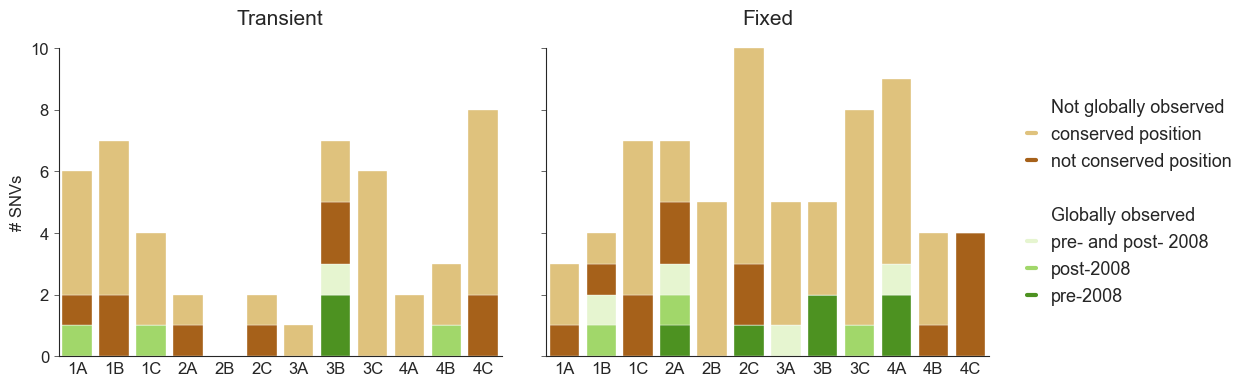

In [25]:
fig = plt.figure(figsize=(12, 4))

gs = gridspec.GridSpec(1,2, wspace=0.1, hspace=0.5, )
non_drift_ax, fix_ax = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

labels = ["pre- and post-2008", "post-2008", "pre-2008", "not observed", "conserved"]
color_list = [ "#01665e", "#5ab4ac", "#c7eae5", "#a6611a", "#dfc27d" ]#
color_list = [ '#4d9221' ,'#a1d76a', '#e6f5d0', "#a6611a", "#dfc27d" ]#

legend_elements = [Line2D([0], [0], color="white", label="Not globally observed", linewidth=0,),
                   Line2D([0], [0], color=color_list[-1], label="conserved position", linewidth=3,  ),
                   Line2D([0], [0], color=color_list[-2], label="not conserved position", linewidth=3,),
                   Line2D([0], [0], color="white", label="", linewidth=0,),
                   Line2D([0], [0], color="white", label="Globally observed", linewidth=0,),
                   Line2D([0], [0], color=color_list[2], label="pre- and post- 2008", linewidth=3,),
                   Line2D([0], [0], color=color_list[1], label="post-2008", linewidth=3,),
                   Line2D([0], [0], color=color_list[0], label="pre-2008", linewidth=3,),]

for j, population in enumerate(populations):
    df = compared_ns_global.loc[population]
    for status, ax in zip(["transient", "fixed"], [non_drift_ax, fix_ax]):
        sdf = df[df["status"]==status]
        bottom  = 0
        for label, col in zip(labels, color_list):
       
            c = len(sdf[sdf["global description"]==label])
            p = ax.bar(j+0.5,  c, bottom=bottom, color=col, edgecolor=None, lw=0.25)
            bottom+= c
            
for ax in [non_drift_ax, fix_ax]:
    ax.set_ylim(0, 10)
    ax.set_yticks(list(range(0,11,2)))
    ax.set_xlim(0, len(populations))
    ax.set_xticks([p+0.5 for p in range(len(populations))])
    
    ax.set_xticklabels(populations, size=12)
    
    ax.tick_params(axis='x', which='both', length=0)
    # ax.tick_params(axis='y', which='both', length=2)
    
    ax.spines[['top','right']].set_visible(False)
    
non_drift_ax.set_yticklabels(list(range(0,11,2)), size=12)
fix_ax.set_yticklabels([])
fix_ax.legend(handles=legend_elements, loc='center left',
           bbox_to_anchor=(1.05,0.5), ncols =1, fontsize=13, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)
fix_ax.set_title("Fixed", y=1.05, size=15)
non_drift_ax.set_title("Transient", y=1.05, size=15)
non_drift_ax.set_ylabel("# SNVs")


## 2 Global rates vs experimental rates



In [26]:
#load trajectories 
trajectories = pd.read_csv("../results/snv_trajectories.csv").set_index(["population", "refname", "nucpos", "snv"]).sort_index()
trajectories = trajectories.rename(columns={c:int(c) for c in trajectories.columns})

### 2.1. Get number of available sites

In [27]:
TnTv = 3
weight_Tn = 3 * TnTv / (1 + TnTv)
weight_Tv = (3 - weight_Tn) / 2


available_sites_per_gene = {}
for segment, sdict in coding_json.items():
    available_sites_per_gene[segment] = {}
    for gene, gdict in sdict.items():
        available_sites_per_gene[segment][gene] = {}
        
        #for each gene get the coding sequence
        gene_seq = Seq("".join([b for i,b in enumerate(segment_nuc_cds[segment]) if i+1 in gdict['nuc_cds_pos']]))
        
        #split seq into codons
        gene_codons = [gene_seq[i:i+3] for i in range(0, len(gene_seq), 3)]
        
        #get number of available sites per mutation type
        stop_sites = count_stop_codon_sites(gene_codons)
        syn_sites = count_syn_codon_sites(gene_codons)
        ns_sites = len(gene_seq) - syn_sites
        
        available_sites_per_gene[segment][gene]["stop"] = stop_sites
        available_sites_per_gene[segment][gene]["syn"] = syn_sites
        available_sites_per_gene[segment][gene]["ns"] = ns_sites
        


In [28]:
#also doing this for the mature H3 > seperating antigenic site for the non-antigenic sites
#for mature H3 get the coding sequence
gene_seq = Seq("".join([b for i,b in enumerate(segment_nuc_cds["4-HA"]) if i+1 in coding_json['4-HA']["HA"]['nuc_cds_pos'] and coding_json['4-HA']["HA"]['pro_aa_pos'][i]>16]))
gene_codons = [gene_seq[i:i+3] for i in range(0, len(gene_seq), 3)]

available_sites_H3 = {}
 
for antigenic in [True, False]:
    if antigenic:
        codons = [codon for i, codon in enumerate(gene_codons) if i+1 in epitope_positions]
       
    else:
        codons = [codon for i, codon in enumerate(gene_codons) if i+1 not in epitope_positions]
         

    # #get number of available sites per mutation type
    stop_sites = count_stop_codon_sites(codons)
    syn_sites = count_syn_codon_sites(codons)
    ns_sites = (len(codons)*3) - syn_sites
    
    if antigenic:
        available_sites_H3["antigenic"] = {"ns":ns_sites, "syn":syn_sites, "stop":stop_sites}
    else:
        available_sites_H3["non-antigenic"] = {"ns":ns_sites, "syn":syn_sites, "stop":stop_sites}
        
    

### 2.2. Estimate experimental rates


Rate of within-host evolution per gene can be calculated via $r = \frac{\sum^{n}_{i}f_{i}}{nt}$  
where $r$ is the rate of evolution per gene, $\sum^{n}_{i}f_{i}$ is the summed frequency of all snvs present at 0.01 frequency (detection limit), $n$ is the number of available sites per mutation type: non-synonymous, synonymous, and missense, and $t$ is the time since infection

In [29]:
freq_cutoff = detection_limit

accumulative_freq_per_site = []
for population in populations:

    timepoints = passages
    
    for segment, sdict in coding_json.items():
        
        try:
            segment_trajec = trajectories.loc[(population, segment), :].dropna(axis=1)

            for gene, gdict in sdict.items():
                gene_nuc_pos = gdict['nuc_cds_pos']
                
                gene_trajec = segment_trajec[segment_trajec.index.get_level_values(0).isin(gene_nuc_pos)].copy()        

                if len(gene_trajec) > 0:
                    for (nucpos, snv) in gene_trajec.index.unique(): 
                        mt = determine_gene_mutation_type(segment, gene, snv)
                        gene_trajec.loc[(nucpos, snv), "mutation type"] = mt
                    
                    for mt in ["ns", "syn", "stop"]:
                        for passage in timepoints: 
                            
                            freqs = gene_trajec[(gene_trajec["mutation type"]==mt)&(gene_trajec[passage]>=freq_cutoff)][passage].values.tolist()

        
                            sites = available_sites_per_gene[segment][gene][mt]  

                            try:
                                cumulative_freq_per_site = sum(freqs) / sites  # new
                            except:
                                cumulative_freq_per_site = 0  # new

                            accumulative_freq_per_site.append([population, segment, gene, mt, passage, cumulative_freq_per_site])

                else:
                    for mt in ["ns", "syn", "stop"]:
                        for passage in timepoints:
                            
                            accumulative_freq_per_site.append([population, segment, gene, mt, passage,  0])

        except KeyError:
            for gene, gdict in sdict.items():
                for mt in ["ns", "syn", "stop"]:
                    for passage in timepoints:
                        
                        accumulative_freq_per_site.append([population, segment, gene, mt, passage,  0])
                  
accumulative_freq_per_site = pd.DataFrame.from_records( accumulative_freq_per_site, columns=["population", "refname", "gene", "mutation type", "passage", "accumalative freq/site"])  # new column)

In [30]:
accumulative_freq_per_sites_genome = []
target_proteins = ["PB2", "PB1", "PA", "HA", "NP", "NA"]

freq_cutoff = detection_limit

for population in populations:
    timepoints = passages
    for passage in timepoints:
        generations = passage * (hours_per_passage / generation_time)
        days = passage *(hours_per_passage/ 24)
        
        # Annotate mutation types and collect all frequencies ONCE per passage
        mt_freqs = {"ns": [], "syn": [], "stop": []}
        
        for segment, sdict in coding_json.items():
            for gene in sdict.keys():
                if gene not in target_proteins:
                    continue
                try:
                    segment_trajec = trajectories.loc[(population, segment), :].dropna(axis=1)
                    gene_nuc_pos = sdict[gene]['nuc_cds_pos']
                    gene_trajec = segment_trajec[segment_trajec.index.get_level_values(0).isin(gene_nuc_pos)].copy()
                    
                    if len(gene_trajec) > 0:
                        for (nucpos, snv) in gene_trajec.index.unique():
                            mut_type = determine_gene_mutation_type(segment, gene, snv)
                            gene_trajec.loc[(nucpos, snv), "mutation type"] = mut_type
                        
                        for mt in ["ns", "syn", "stop"]:
                            freqs = gene_trajec[(gene_trajec["mutation type"] == mt) & (gene_trajec[passage] >= freq_cutoff)][passage].values.tolist()
                            mt_freqs[mt].extend(freqs)
                
                except:
                    continue
        
        for mt in ["ns", "syn", "stop"]:
            total_available_sites = sum(available_sites_per_gene[segment][gene][mt] for segment, sdict in coding_json.items() 
                                        for gene in sdict.keys() if gene in target_proteins)
            try:

                cumulative_freq_per_site = sum(mt_freqs[mt]) / total_available_sites
                
            except:
                
                cumulative_freq_per_site = 0 
            
            accumulative_freq_per_sites_genome.append([ population, mt, passage, cumulative_freq_per_site])

accumulative_freq_per_sites_genome = pd.DataFrame.from_records( accumulative_freq_per_sites_genome,columns=["population", "mutation type", "passage", "accumalative freq/site"])

In [31]:
accumulative_freq_per_site_HA = []
for population in populations:
    timepoints = passages
    HA_trajec = trajectories.loc[(population, "4-HA"), :].dropna(axis=1)
    
    #nucpos to mature H3 aapos 
    nucpos_H3 = {i[0]:int(row["aapos"]-16) for i, row in  snv_summary.loc[(population, "4-HA")].iterrows() if row["aapos"]-16>0}

    for antigenic in [True, False]:
        if antigenic:
            snv_targets = [k for k,v in nucpos_H3.items() if v in epitope_positions]
            stop_sites = available_sites_H3["antigenic"]["stop"]
            ns_sites = available_sites_H3["antigenic"]["ns"]
            syn_sites = available_sites_H3["antigenic"]["syn"]

        else:
            snv_targets = [k for k,v in nucpos_H3.items() if v not in epitope_positions]
            stop_sites = available_sites_H3["non-antigenic"]["stop"]
            ns_sites = available_sites_H3["non-antigenic"]["ns"]
            syn_sites = available_sites_H3["non-antigenic"]["syn"]

        site_trajec = HA_trajec.loc[snv_targets]
        for (nucpos, snv) in site_trajec.index.unique(): 
            
        
            #doing this manually
            if snv_summary.loc[(population, "4-HA", nucpos, snv), "aa_mut"].values[-1] == "*":
                site_trajec.loc[(nucpos, snv), "mutation type"] = "stop"
            elif any(snv_summary.loc[(population, "4-HA", nucpos, snv), "non_synonymous"]):
                site_trajec.loc[(nucpos, snv), "mutation type"] = "ns"
            else:
                site_trajec.loc[(nucpos, snv), "mutation type"] = "syn"
        
        for i, mt in enumerate(["ns", "syn", "stop"]):
            n_sites = [ns_sites, syn_sites, stop_sites][i]

            #calculate rate per time point
            for passage in passages: 
                
                freqs = site_trajec[(site_trajec["mutation type"]==mt)&(site_trajec[passage]>=freq_cutoff)][passage].values.tolist()
                
                
                try:
                    
                    cumulative_freq_per_site = sum(freqs) / n_sites  
                    
                except: #skipping passage 0

                    cumulative_freq_per_site = 0

                accumulative_freq_per_site_HA.append([population, "antigenic" if antigenic else "non-antigenic",  mt, passage,  cumulative_freq_per_site])

        
accumulative_freq_per_site_HA = pd.DataFrame.from_records(accumulative_freq_per_site_HA, columns=["population", "site","mutation type", "passage", "accumalative freq/site"])

#### 2.2.1. Linear regression to estimate the rate

Text(0.5, 1.0, 'Synonymous')

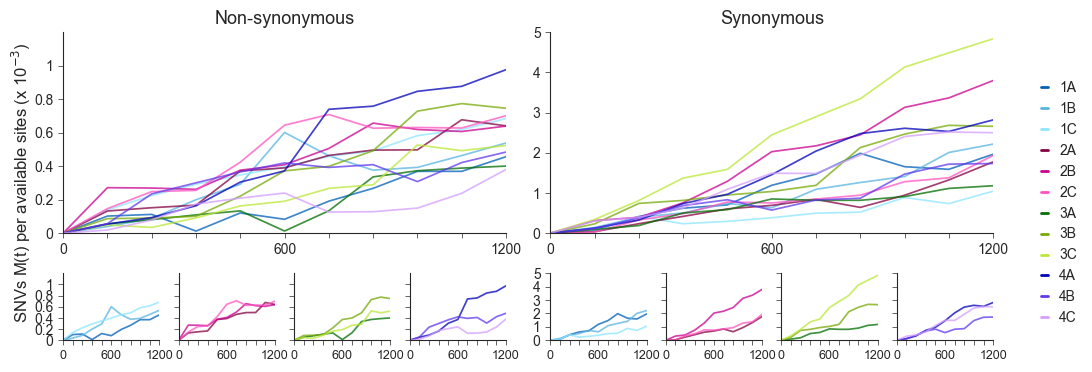

In [32]:
fig = plt.figure(figsize=(12,4))

population_legend_elements = []
for i, population in enumerate(populations):
    population_legend_elements.append(Line2D([0], [0], color=population_cpal[i], label=population, linewidth=2,  ))


gs = gridspec.GridSpec(1,2, wspace=0.1, hspace=0.5,)

gsi = gridspec.GridSpecFromSubplotSpec(2,1,  subplot_spec=gs[0], wspace=0.25, hspace=0.3, height_ratios=[3,1])
all_ax = fig.add_subplot(gsi[0])
gsij = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsi[1], hspace=0.3, wspace=0.2)
donor_axes = [fig.add_subplot(gsij[0]), fig.add_subplot(gsij[1]), fig.add_subplot(gsij[2]), fig.add_subplot(gsij[3])]

df = accumulative_freq_per_sites_genome.copy().set_index([ "mutation type", "population", "passage"]).sort_index().loc["ns"]
for i, population in enumerate(populations):
    values = df.loc[(population), "accumalative freq/site"].tolist()
    all_ax.plot(passages,values, lw=1.25, alpha=0.75, color=population_cpal[i])
    donor_axes[donors.index(int(population[0]))].plot(passages,values, lw=1.25, alpha=0.75, color=population_cpal[i])
    
    
for ax in [all_ax] + donor_axes:
    ax.set_ylim(0, 0.0012)  
    ax.set_yticks([0,2e-4,4e-4,6e-4,8e-4,10e-4,])
    ax.set_yticklabels([])
    ax.spines[['top','right',]].set_visible(False)
    ax.set_xlim(0, 100)
    ax.set_xticks(passages)
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages], size=9)
all_ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages], size=10)
all_ax.set_yticklabels([0,0.2,0.4,0.6,0.8,1])
donor_axes[0].set_yticklabels([0,0.2,0.4,0.6,0.8,1])

all_ax.text(-12, 3e-4, "SNVs M(t) per available sites (x 10" + r"$^{-3}$" + ")", size=12, rotation=90, va="center")
all_ax.set_title("Non-synonymous", size=13)


gsi = gridspec.GridSpecFromSubplotSpec(2,1,  subplot_spec=gs[1], wspace=0.25, hspace=0.3, height_ratios=[3,1])
all_ax = fig.add_subplot(gsi[0])
gsij = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsi[1], hspace=0.3, wspace=0.2)
donor_axes = [fig.add_subplot(gsij[0]), fig.add_subplot(gsij[1]), fig.add_subplot(gsij[2]), fig.add_subplot(gsij[3])]


df = accumulative_freq_per_sites_genome.copy().set_index([ "mutation type", "population", "passage"]).sort_index().loc["syn"]
for i, population in enumerate(populations):
    values = df.loc[(population), "accumalative freq/site"].tolist()
    all_ax.plot(passages,values, lw=1.25, alpha=0.75, color=population_cpal[i])
    
    
    donor_axes[donors.index(int(population[0]))].plot(passages,values, lw=1.25, alpha=0.75, color=population_cpal[i])

for ax in [all_ax] + donor_axes:
    ax.set_ylim(0, 0.005)  
    ax.set_yticks([0, 1e-3, 2e-3, 3e-3, 4e-3, 5e-3])
    ax.set_yticklabels([])
    ax.spines[['top','right',]].set_visible(False)
    ax.set_xlim(0, 100)
    ax.set_xticks(passages)
    ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages], size=9)
all_ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages], size=10)
all_ax.set_yticklabels([0,1,2,3,4,5])
donor_axes[0].set_yticklabels([0,1,2,3,4,5])

all_ax.legend(handles=population_legend_elements, loc='center left',  bbox_to_anchor=(1.08,0.15), 
              ncols =1, fontsize=10, handlelength=0.5, edgecolor=None, frameon=False,  columnspacing=0.5)
all_ax.set_title("Synonymous", size=13)
    


In [33]:
#rates look pretty linear so let's see if we can estimated the rate of evolution via linear regression
within_host_rates_genome = []
for population in populations:
    for mt in ["ns", "syn"]:
        timepoints = passages
        
        df = accumulative_freq_per_sites_genome.copy()
        df = df[(df["population"]==population)&(df["mutation type"]==mt)]
        
        #per generation
        timepoints = [(p*hours_per_passage)/generation_time for p in passages]
        slope, intercept, rvalue, pvalue, stderr = linregress(timepoints, df["accumalative freq/site"])
        n = len(df)
        ci = t.ppf(0.975, n - 2) * stderr
        if rvalue**2 <0.75:
            print (f"lower r2 value for {population} {mt}: {rvalue**2}")
        within_host_rates_genome.append([population, mt, "per generation", slope, slope-ci, slope+ci, intercept, rvalue, pvalue, stderr])
        
        
        #per day
        timepoints = [(p*hours_per_passage)/24 for p in passages]
        slope, intercept, rvalue, pvalue, stderr = linregress(timepoints, df["accumalative freq/site"])
        ci = t.ppf(0.975, n - 2) * stderr
        # if rvalue**2 <0.75:
        #     print (f"lower r2 value for {population} {mt}: {rvalue**2}")
        within_host_rates_genome.append([population, mt, "per day", slope, slope-ci, slope+ci, intercept, rvalue, pvalue, stderr])
        
        
        

within_host_rates_genome = pd.DataFrame.from_records(within_host_rates_genome, columns=["population", "mutation type", "time unit", "slope", "ci low", "ci upper", "intercept", "rvalue", "p", "stderr"])


lower r2 value for 1B ns: 0.7244972888665865
lower r2 value for 4B ns: 0.7135074614949972
lower r2 value for 4C ns: 0.6114189151855492


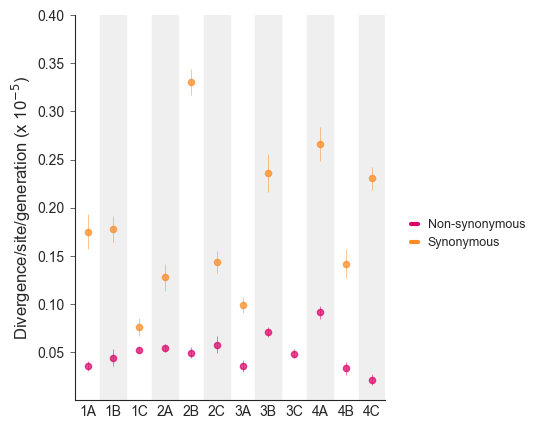

In [34]:
fig, ax = plt.subplots(1,1, figsize=(4,5))

df = within_host_rates_genome[within_host_rates_genome["time unit"]=="per generation"].set_index(["population", "mutation type"])


for i, population in enumerate(populations):
    y = df.loc[(population, "ns"), "slope"]
    ye = df.loc[(population, "ns"), "stderr"]
    sc = ax.scatter(i, y, color=nonsyn_color, s=20, alpha=0.7)
    ax.errorbar(i, y, yerr=ye,zorder=-10, alpha=0.7, color=nonsyn_color, lw=0.5, clip_on=True)
    
    y = df.loc[(population, "syn"), "slope"]
    ye = df.loc[(population, "syn"), "stderr"]
    sc = ax.scatter(i, y, color=syn_color, s=20, alpha=0.7)
    ax.errorbar(i, y, yerr=ye,zorder=-10, alpha=0.7, color=syn_color, lw=0.5, clip_on=True)
    
ax.set_ylim(0, 4e-6)
ax.set_yticks([0.05e-5, 0.1e-5,0.15e-5, 0.2e-5,0.25e-5, 0.3e-5, 0.35e-5, 0.4e-5,])
ax.set_yticklabels(['0.05', '0.10', '0.15', '0.20','0.25','0.30', '0.35', '0.40',])
ax.text(-3, 0.2e-5, "Divergence/site/generation (x 10" + r"$^{-5}$" + ")", size=12, rotation=90, va="center")



ax.set_xticks(range(len(populations)))
ax.set_xticklabels(populations)
ax.tick_params(axis='x', which='both', length=0) 
numbered = range(len(populations))
for x0, x1 in zip(numbered[::2], numbered[1::2]):
    ax.axvspan(x0+0.5, x1+0.5, color="#efefef", zorder=-2000, alpha = 1)
ax.set_xlim(-0.5, len(populations)-0.5)
ax.spines[['top','right',]].set_visible(False)

legend_elements = []#[Line2D([0], [0], color='white', label="population", linewidth=0,)]
for color, label in zip([nonsyn_color, syn_color], 
                        ["Non-synonymous", "synonymous", ]):
    legend_elements.append(Line2D([0], [0], color=color, label=label.capitalize(), linewidth=3,  ))
ax.legend(handles=legend_elements, loc='upper left',  
                                bbox_to_anchor=(1.05, 0.5), ncols =1, fontsize=9, handlelength=0.5, edgecolor=None, frameon=False, 
                                columnspacing=0.5)

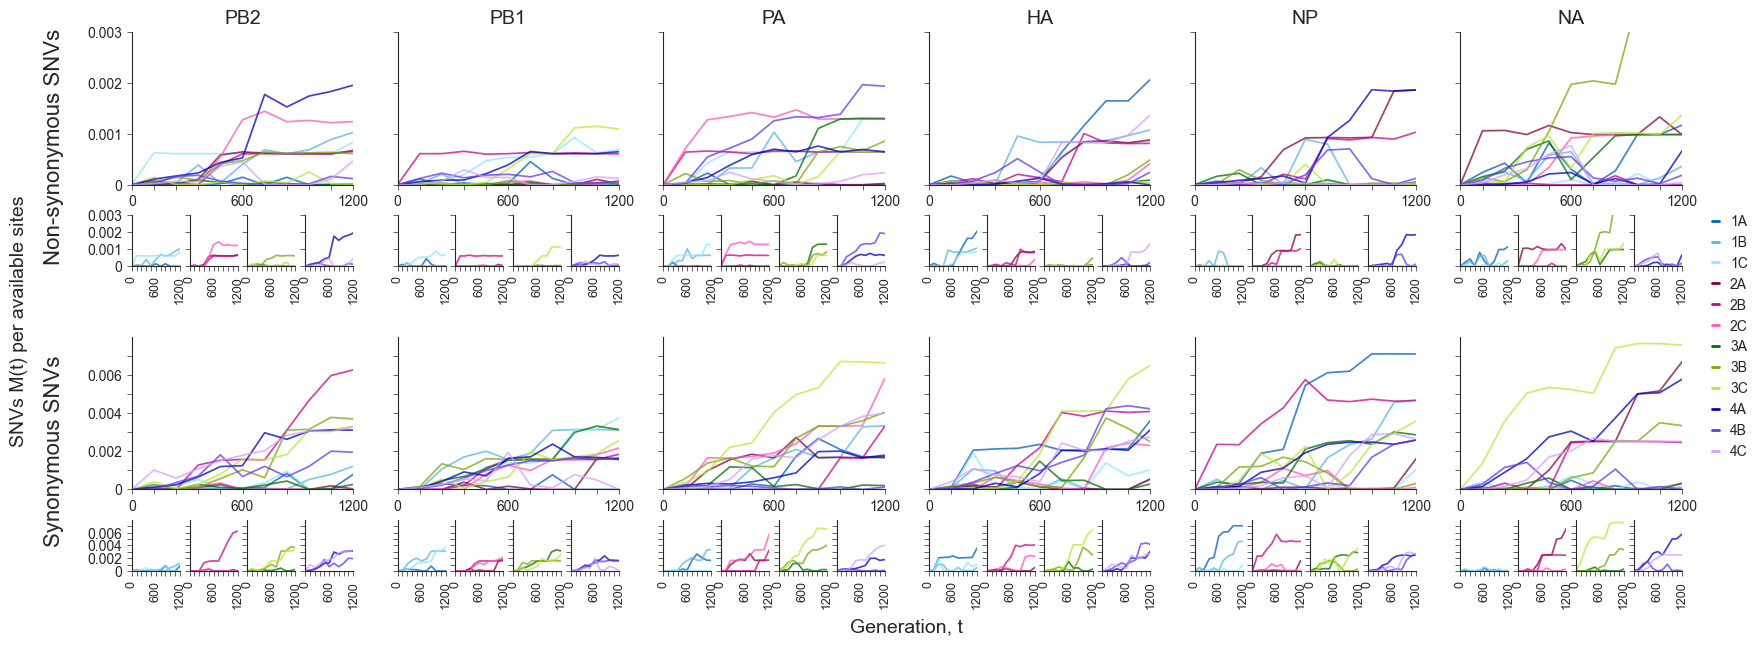

In [35]:
#per segment

fig = plt.figure(figsize=(20,7))

population_legend_elements = []
for i, population in enumerate(populations):
    population_legend_elements.append(Line2D([0], [0], color=population_cpal[i], label=population, linewidth=2,  ))


gs = gridspec.GridSpec(2,6, wspace=0.2, hspace=0.3,)

for pidx, protein in enumerate(target_proteins):
    
    #non-syn
    gsi = gridspec.GridSpecFromSubplotSpec(2,1,  subplot_spec=gs[0,pidx], wspace=0.25, hspace=0.3, height_ratios=[3,1])
    all_ax = fig.add_subplot(gsi[0])
    gsij = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsi[1], hspace=0.3, wspace=0.2)
    donor_axes = [fig.add_subplot(gsij[0]), fig.add_subplot(gsij[1]), fig.add_subplot(gsij[2]), fig.add_subplot(gsij[3])]
    
    df = accumulative_freq_per_site.copy()
    df = df[df["gene"]==protein].set_index([ "mutation type", "population", "passage"]).sort_index().loc["ns"]
    for i, population in enumerate(populations):
        values = df.loc[(population), "accumalative freq/site"].tolist()
        all_ax.plot(passages,values, lw=1.25, alpha=0.75, color=population_cpal[i])
        donor_axes[donors.index(int(population[0]))].plot(passages,values, lw=1.25, alpha=0.75, color=population_cpal[i])
    

    for ax in [all_ax] + donor_axes:
        ax.set_ylim(0, 0.003)  
        ax.set_yticks([0,0.001, 0.002, 0.003,])
        ax.set_yticklabels([])
        ax.spines[['top','right',]].set_visible(False)
        ax.set_xlim(0, 100)
        ax.set_xticks(passages)
        ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages], size=9, rotation=90 if ax in donor_axes else 0)
    all_ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages], size=10)
    if pidx ==0:
        all_ax.set_yticklabels([0,0.001, 0.002, 0.003,])
        donor_axes[0].set_yticklabels([0,0.001, 0.002, 0.003,])
        all_ax.text(-0.35, 0.25, 'Non-synonymous SNVs', ha='center', va='center',transform=all_ax.transAxes, rotation=90, clip_on=False, size=16,
                    )
        
    all_ax.set_title(protein)
        
    #syn
    gsi = gridspec.GridSpecFromSubplotSpec(2,1,  subplot_spec=gs[1,pidx], wspace=0.25, hspace=0.3, height_ratios=[3,1])
    all_ax = fig.add_subplot(gsi[0])
    gsij = gridspec.GridSpecFromSubplotSpec(1,4, subplot_spec=gsi[1], hspace=0.3, wspace=0.2)
    donor_axes = [fig.add_subplot(gsij[0]), fig.add_subplot(gsij[1]), fig.add_subplot(gsij[2]), fig.add_subplot(gsij[3])]
    
    df = accumulative_freq_per_site.copy()
    df = df[df["gene"]==protein].set_index([ "mutation type", "population", "passage"]).sort_index().loc["syn"]
    for i, population in enumerate(populations):
        values = df.loc[(population), "accumalative freq/site"].tolist()
        all_ax.plot(passages,values, lw=1.25, alpha=0.75, color=population_cpal[i])
        donor_axes[donors.index(int(population[0]))].plot(passages,values, lw=1.25, alpha=0.75, color=population_cpal[i])
    

    for ax in [all_ax] + donor_axes:
        ax.set_ylim(0, 0.008)  
        ax.set_yticks([0,0.001, 0.002, 0.003, 0.004, 0.005, 0.006 ,0.007])
        ax.set_yticklabels([])
        ax.spines[['top','right',]].set_visible(False)
        ax.set_xlim(0, 100)
        ax.set_xticks(passages)
        ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages], size=9, rotation=90 if ax in donor_axes else 0)
    all_ax.set_xticklabels([int((p*hours_per_passage)/generation_time) if p %50==0 else "" for p in passages], size=10)
    
    if pidx ==0:
        all_ax.set_yticklabels([0, '', 0.002, '', 0.004, '', 0.006,  ''])
        donor_axes[0].set_yticklabels([0, '', 0.002,'', 0.004,'', 0.006, ''])
        
        all_ax.text(-0.35, 0.25, 'Synonymous SNVs', ha='center', va='center',transform=all_ax.transAxes, rotation=90, clip_on=False, size=16,)
        

        all_ax.text(-0.55, 1.1, "SNVs M(t) per available sites", transform=all_ax.transAxes, size=14, rotation=90, va="center")
    if pidx == 2:
        all_ax.text(1.1, -0.9, "Generation, t", transform=all_ax.transAxes, size=14, rotation=0, va="center", ha="center")
        
# all_ax.set_title("Non-synonymous", size=13)


all_ax.legend(handles=population_legend_elements, loc='center left',  bbox_to_anchor=(1.08,1), 
              ncols =1, fontsize=10, handlelength=0.5, edgecolor=None, frameon=False,  columnspacing=0.5)

    


Not estimating rates per gene to little data to do so properly

### 2.3. Estimate global rates
I have aligned all download GISAID (download specific are described in the README.md) against the starting virus CDS files per segment per year subsampling to 100 random sequences per year. This data cannot be shared and should therefore be downloaded and aligned by the users themselves if desired. the GISAID ids for sequences selected for rate estimation can be found [here](../results/global_data/GISAID_sequence_Ids_for_rate_estimation.csv).


In [36]:
global_rate_file= "../results/global_data/estimated_global_rates.csv"
global_aligned_dir = "../results/global_data/aligned_to_starting_virus"

starting_virus_date  = pd.to_datetime("2008-05-11")# collection date A/Japan/WRAIR1059P/2008 


global_rate_overview = []
random.seed(23455648192)


sample_size = 100
selected_ids =[]
if not os.path.isfile(global_rate_file):
    for f in os.listdir(global_aligned_dir):
        try: year = int(f.split("_")[-1].rstrip(".fasta"))
        except: continue
        
        if year < 2008: continue
        refname = f.split("_")[0]
        
        stock_seq = segment_nuc_cds[refname]
        
        
        for gene, gdict in coding_json[refname].items():
            records = [r for r in SeqIO.parse(os.path.join(global_aligned_dir, f), "fasta")][1:] #skipping first sequences as it the stock virus 
            
            records_ids = [r.id for r in records]
            record_seqs = ["".join([r.seq[p-1] for p in gdict["nuc_cds_pos"]])for r in records]
            
            #need to remove all sequences that dont have only valid nucleotides
            valid_records = []
            for rid, rseq in zip(records_ids, record_seqs):
                try:d = pd.to_datetime(rid.split("|")[4])
                except:continue
                if d <= starting_virus_date:
                    continue
                
                if all(b in valid_nucs for b in rseq):
                    valid_records.append((rid, rseq))
            
            #subsample to sample size
            try:
                valid_records = random.sample(valid_records, sample_size ) 
            except:
                pass
            
            for (rid, rseq )in valid_records:
                selected_ids.append([refname, gene, year, rid])
                d = pd.to_datetime(rid.split("|")[4])
                days = ((d - starting_virus_date).days)
                
                muts = determine_global_snvs(stock_seq, rseq)
                muts = [m for m in muts if int(m[1:-1]) in gdict["nuc_cds_pos"]]

                mut_dict = {"ns":[], "syn":[], "stop":[]}
                for snv in muts:
                    mt = determine_gene_mutation_type(refname, gene, snv)
                    mut_dict[mt].append(snv)
                    
                
                for mt, snv_list in mut_dict.items():
                    rate = len(snv_list)/(available_sites_per_gene[refname][gene][mt]*days)
                    
                    global_rate_overview.append([refname, gene, year, mt, rate, rid.split("|")[0], days, len(snv_list), available_sites_per_gene[refname][gene][mt]])
        
    global_rate_overview = pd.DataFrame.from_records(global_rate_overview, columns=["refname", "gene", "year", "mt", "divergence/site/day", "Isolate_Id", "days", "n_snvs", "available_sites"])
    global_rate_overview = global_rate_overview.sort_values(["refname", "gene", "year", "mt"], ignore_index=True)
    global_rate_overview.to_csv(global_rate_file, index=False)   
    
    df = pd.DataFrame.from_records(selected_ids, columns=["refname", "gene", "year", "full id"])
    df["Isolate_Id"] = [i.split('|')[0] for i in df["full id"]]
    df["Segment_Id"] = [i.split('|')[1] for i in df["full id"]]
    df = df.sort_values(["refname", "gene", "year"], ignore_index=True).drop(columns="full id")
    df.to_csv("../results/global_data/GISAID_sequence_Ids_for_rate_estimation.csv", index=False)
    
    
else:
    global_rate_overview = pd.read_csv(global_rate_file, keep_default_na=False, na_values=[""])
    
for i, row in global_rate_overview.iterrows():
    global_rate_overview.loc[i, "available_sites"] = available_sites_per_gene[row["refname"]][row["gene"]][row['mt']]

In [37]:
target_proteins = ["PB2", "PB1", "PA", "HA", "NP", "NA"]
global_rate_genome = global_rate_overview[global_rate_overview["gene"].isin(target_proteins)]

# sum n_muts and avail_sites across genes per sequence, then divide
global_rate_genome = global_rate_genome.groupby(["year", "mt", "Isolate_Id", "days"])[["n_snvs", "available_sites"]].sum().reset_index()
global_rate_genome["divergence/site/day"] = global_rate_genome["n_snvs"] / (global_rate_genome["available_sites"] * global_rate_genome["days"])


rate_results = []
for mt, group in global_rate_genome.groupby(["mt"]):
    group = group.copy()
    group["div_per_site"] = group["n_snvs"] / group["available_sites"]
    slope, intercept, r, p, se = linregress(group["days"], group["div_per_site"])
    rate_results.append([ mt[0],slope, se ,p,r**2,len(group)])
rate_results = pd.DataFrame(rate_results, columns=["mt",  "divergence/site/day", "se", "p", "r2", "n"]).set_index("mt").sort_index()

rate_results_gene = []
target_proteins = ["PB2", "PB1", "PA", "HA", "NP", "NA"]
for gene in target_proteins:
    global_rate_gene = global_rate_overview[global_rate_overview["gene"]==gene].copy()
    global_rate_gene["divergence/site/day"] = global_rate_gene["n_snvs"] / (global_rate_gene["available_sites"] * global_rate_gene["days"])
    for mt, group in global_rate_gene.groupby(["mt"]):
        group = group.copy()
        group["div_per_site"] = group["n_snvs"] / group["available_sites"]
        slope, intercept, r, p, se = linregress(group["days"], group["div_per_site"])
        rate_results_gene.append([gene, mt[0],slope, se ,p,r**2,len(group)])
    
rate_results_gene = pd.DataFrame(rate_results_gene, columns=["gene", "mt",  "divergence/site/day", "se", "p", "r2", "n"]).set_index(["gene","mt"]).sort_index()


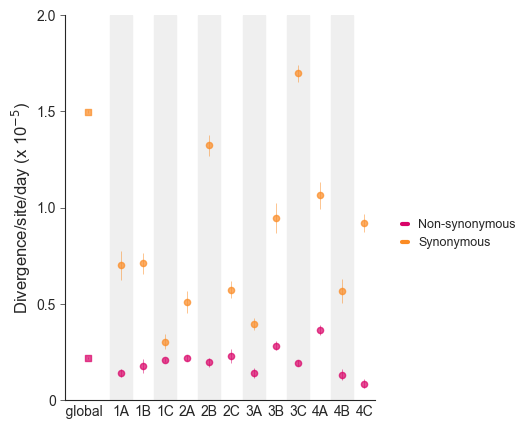

In [38]:
fig, ax = plt.subplots(1,1, figsize=(4,5))

df = within_host_rates_genome[within_host_rates_genome["time unit"]=="per day"].set_index(["population", "mutation type"])


for i, population in enumerate(populations):
    y = df.loc[(population, "ns"), "slope"]
    ye = df.loc[(population, "ns"), "stderr"]
    sc = ax.scatter(i, y, color=nonsyn_color, s=20, alpha=0.7)
    ax.errorbar(i, y, yerr=ye,zorder=-10, alpha=0.7, color=nonsyn_color, lw=0.5, clip_on=True)
    
    y = df.loc[(population, "syn"), "slope"]
    ye = df.loc[(population, "syn"), "stderr"]
    sc = ax.scatter(i, y, color=syn_color, s=20, alpha=0.7)
    ax.errorbar(i, y, yerr=ye,zorder=-10, alpha=0.7, color=syn_color, lw=0.5, clip_on=True)
    
y = rate_results.loc["ns", "divergence/site/day"]
ye= rate_results.loc["ns", "se"]
ax.scatter(-1.5,y, color=nonsyn_color, s=25, alpha=0.7, marker="s")
ax.errorbar(-1.5, y, yerr=ye,zorder=-10, alpha=0.7, color=nonsyn_color, lw=0.5, clip_on=True)

y =rate_results.loc["syn", "divergence/site/day"]
ye= rate_results.loc["syn", "se"]
ax.scatter(-1.5, y, color=syn_color, s=25, alpha=0.7, marker="s")
ax.errorbar(-1.5, y, yerr=ye,zorder=-10, alpha=0.7, color=syn_color, lw=0.5, clip_on=True)
    
ax.set_ylim(0, 2e-5)
ax.set_yticks([0,0.5e-5, 1e-5, 1.5e-5, 2e-5, ])
ax.set_yticklabels(['0', '0.5', '1.0', '1.5', '2.0',])
ax.text(-5, 1e-5, "Divergence/site/day (x 10" + r"$^{-5}$" + ")", size=12, rotation=90, va="center")


ax.set_xticks(range(-2, len(populations)))
ax.set_xticklabels(["    global", ""]+ populations)
ax.tick_params(axis='x', which='both', length=0) 
numbered = range(-1, len(populations))
for x0, x1 in zip(numbered[::2], numbered[1::2]):
    ax.axvspan(x0+0.5, x1+0.5, color="#efefef", zorder=-2000, alpha = 1)
ax.set_xlim(-2.5, len(populations)-0.5)
ax.spines[['top','right',]].set_visible(False)

legend_elements = []#[Line2D([0], [0], color='white', label="population", linewidth=0,)]
for color, label in zip([nonsyn_color, syn_color], 
                        ["Non-synonymous", "synonymous", ]):
    legend_elements.append(Line2D([0], [0], color=color, label=label.capitalize(), linewidth=3,  ))
ax.legend(handles=legend_elements, loc='upper left',  
                                bbox_to_anchor=(1.05, 0.5), ncols =1, fontsize=9, handlelength=0.5, edgecolor=None, frameon=False, 
                                columnspacing=0.5)

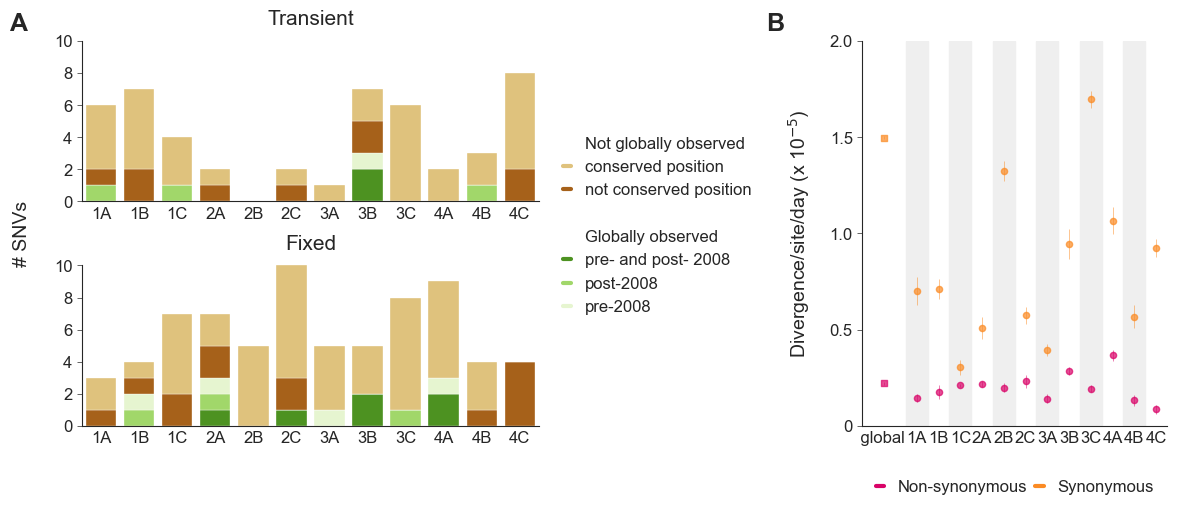

In [39]:
fig = plt.figure(figsize=(14,5))

# gs = gridspec.GridSpec(1, 2, wspace=0.3, hspace=0.3, width_ratios=[1,1.5])
gs = gridspec.GridSpec(1, 2, wspace=0.85, hspace=0.6, width_ratios=[1.5,1])

ax = fig.add_subplot(gs[-1])
 
df = within_host_rates_genome[within_host_rates_genome["time unit"]=="per day"].set_index(["population", "mutation type"])


for i, population in enumerate(populations):
    y = df.loc[(population, "ns"), "slope"]
    ye = df.loc[(population, "ns"), "stderr"]
    sc = ax.scatter(i, y, color=nonsyn_color, s=20, alpha=0.7)
    ax.errorbar(i, y, yerr=ye,zorder=-10, alpha=0.7, color=nonsyn_color, lw=0.5, clip_on=True)
    
    y = df.loc[(population, "syn"), "slope"]
    ye = df.loc[(population, "syn"), "stderr"]
    sc = ax.scatter(i, y, color=syn_color, s=20, alpha=0.7)
    ax.errorbar(i, y, yerr=ye,zorder=-10, alpha=0.7, color=syn_color, lw=0.5, clip_on=True)
    
y = rate_results.loc["ns", "divergence/site/day"]
ye= rate_results.loc["ns", "se"]
ax.scatter(-1.5,y, color=nonsyn_color, s=25, alpha=0.7, marker="s")
ax.errorbar(-1.5, y, yerr=ye,zorder=-10, alpha=0.7, color=nonsyn_color, lw=0.5, clip_on=True)

y =rate_results.loc["syn", "divergence/site/day"]
ye= rate_results.loc["syn", "se"]
ax.scatter(-1.5, y, color=syn_color, s=25, alpha=0.7, marker="s")
ax.errorbar(-1.5, y, yerr=ye,zorder=-10, alpha=0.7, color=syn_color, lw=0.5, clip_on=True)
    
ax.set_ylim(0, 2e-5)
ax.set_yticks([0,0.5e-5, 1e-5, 1.5e-5, 2e-5, ])
ax.set_yticklabels(['0', '0.5', '1.0', '1.5', '2.0',], size=12)
ax.text(-6, 1e-5, "Divergence/site/day (x 10" + r"$^{-5}$" + ")", size=14, rotation=90, va="center")


ax.set_xticks(range(-2, len(populations)))
ax.set_xticklabels(["    global", ""]+ populations, size=12)
ax.tick_params(axis='x', which='both', length=0) 
numbered = range(-1, len(populations))
for x0, x1 in zip(numbered[::2], numbered[1::2]):
    ax.axvspan(x0+0.5, x1+0.5, color="#efefef", zorder=-2000, alpha = 1)
ax.set_xlim(-2.5, len(populations)-0.5)
ax.spines[['top','right',]].set_visible(False)

legend_elements = []#[Line2D([0], [0], color='white', label="population", linewidth=0,)]
for color, label in zip([nonsyn_color, syn_color], 
                        ["Non-synonymous", "synonymous", ]):
    legend_elements.append(Line2D([0], [0], color=color, label=label.capitalize(), linewidth=3,  ))
ax.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncols =2, fontsize=12, handlelength=0.5, edgecolor=None, frameon=False,  columnspacing=0.5)
#ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1, 0.5), ncols =1, fontsize=12, handlelength=0.5, edgecolor=None, frameon=False,  columnspacing=0.5)


gsi =gridspec.GridSpecFromSubplotSpec(2,1, wspace=0.1, hspace=0.4, subplot_spec=gs[0],)
non_drift_ax, fix_ax = fig.add_subplot(gsi[0]), fig.add_subplot(gsi[1])


labels = ["pre- and post-2008", "post-2008", "pre-2008", "not observed", "conserved"]

color_list = [ '#4d9221' ,'#a1d76a', '#e6f5d0', "#a6611a", "#dfc27d" ]#
#color_list = [ "#4d9221", "#a1d76a", "#e6f5d0", "#9970ab", "#c2a5cf" ]

# color_list = [ '#134611' ,'#3e8914', '#96e072','#9d4edd', '#3c096c']


legend_elements = [Line2D([0], [0], color="white", label="Not globally observed", linewidth=0,),
                   Line2D([0], [0], color=color_list[-1], label="conserved position", linewidth=3,  ),
                   Line2D([0], [0], color=color_list[-2], label="not conserved position", linewidth=3,),
                   Line2D([0], [0], color="white", label="", linewidth=0,),
                   Line2D([0], [0], color="white", label="Globally observed", linewidth=0,),
                   Line2D([0], [0], color=color_list[0], label="pre- and post- 2008", linewidth=3,),
                   Line2D([0], [0], color=color_list[1], label="post-2008", linewidth=3,),
                   Line2D([0], [0], color=color_list[2], label="pre-2008", linewidth=3,),]

for j, population in enumerate(populations):
    df = compared_ns_global.loc[population]
    for status, ax in zip(["transient", "fixed"], [non_drift_ax, fix_ax]):
        sdf = df[df["status"]==status]
        bottom  = 0
        for label, col in zip(labels, color_list):
       
            c = len(sdf[sdf["global description"]==label])
            p = ax.bar(j+0.5,  c, bottom=bottom, color=col, edgecolor=None, lw=0.25)
            bottom+= c
            
for ax in [non_drift_ax, fix_ax]:
    ax.set_ylim(0, 10)
    ax.set_yticks(list(range(0,11,2)))
    ax.set_xlim(0, len(populations))
    ax.set_xticks([p+0.5 for p in range(len(populations))])
    
    ax.set_xticklabels(populations, size=12)
    
    ax.tick_params(axis='x', which='both', length=0)
    # ax.tick_params(axis='y', which='both', length=2)
    
    ax.spines[['top','right']].set_visible(False)
    
non_drift_ax.set_yticklabels(list(range(0,11,2)), size=12)
fix_ax.set_yticklabels(list(range(0,11,2)), size=12)

# fix_ax.set_yticklabels([])
fix_ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.02,1.25), ncols =1, fontsize=12, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)
fix_ax.set_title("Fixed", y=1.05, size=15)
non_drift_ax.set_title("Transient", y=1.05, size=15)
# non_drift_ax.set_ylabel("# SNVs", size=14)
non_drift_ax.text(-1.8, -2, "# SNVs", size=14, rotation=90, va="center")

fig.text(0.08, 0.9, "A", ha="center", size=18, fontweight="bold")
fig.text(0.62, 0.9, "B", ha="center", size=18, fontweight="bold")

# fig.savefig("../figures/fig6_experimental_vs_global.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/fig6_experimental_vs_global.png", dpi=300,bbox_inches='tight')  

**Figure 6 Experimental evolution vs global evolution**. **A**, Number of non-drift-like AA mutations per population grouped by global observation patterns. **B**, Global and experimental rates of evolution at synonymous and non-synonymous sites within the PB2, PB1, PA, HA, NP, and NA genes. Experimental rates and global rates are shown as the mean and standard error calculated through linear regression